# Phase 7 — Real A/B test: Cookie Cats (gate at level 30 vs 40)

**Data:** Cookie Cats, a mobile puzzle game by Tactile Entertainment. Players were randomly assigned at install to `gate_30` (control: first gate at level 30) or `gate_40` (treatment: gate moved to level 40). Public dataset (DataCamp project, also on Kaggle as *Mobile Games A/B Testing - Cookie Cats*), one row per player:

| column | meaning |
|---|---|
| `userid` | player id |
| `version` | `gate_30` / `gate_40` |
| `sum_gamerounds` | rounds played in the first 14 days after install |
| `retention_1` | came back 1 day after install |
| `retention_7` | came back 7 days after install |

This is **real** experiment data — unlike Phase 6, which is a design only.

**Decision to make:** should Tactile move the gate to level 40? Primary metric: 7-day retention (long-term engagement). Secondary: 1-day retention. Guardrail-style check: game rounds.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from streampulse.db import query, t, save_result, banner, RESULTS_DIR, IS_FIXTURE

banner()
FIG = RESULTS_DIR / "figures"
FIG.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
import hashlib
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

DATA = ROOT / "data" / "raw" / "cookie_cats.csv"
EXPECTED_ROWS = 90_189

target=duckdb  results -> results


## 7.1 Load and verify the file
The row count and checksum let anyone confirm they analysed the same file.

In [2]:
raw = DATA.read_bytes()
sha256 = hashlib.sha256(raw).hexdigest()
ab = pd.read_csv(DATA)
print(f"rows={len(ab):,}  sha256={sha256}")
assert len(ab) == EXPECTED_ROWS, "unexpected row count - different file version?"
assert ab.userid.is_unique, "a player appears twice"
assert set(ab.version) == {"gate_30", "gate_40"}
ab.head()

rows=90,189  sha256=5ab54d761fbddcd50de7b88e4eaf7837cba4569474f50c043a4d17ee342c46bd


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 7.2 Sample ratio mismatch (SRM) check — always first
If randomisation was 50/50, group sizes should be close to equal. A chi-square goodness-of-fit test asks: *is this split too uneven to be chance?* A tiny p-value (convention: < 0.01) means assignment or logging may be broken, and every downstream result is suspect.

In [3]:
counts = ab.version.value_counts().sort_index()
expected = np.full(2, counts.sum() / 2)
chi2, srm_p = stats.chisquare(counts.values, expected)
print(counts.to_string())
print(f"split: {counts.iloc[0] / counts.sum():.4%} / {counts.iloc[1] / counts.sum():.4%}")
print(f"SRM chi-square = {chi2:.2f}, p = {srm_p:.4g}  -> {'SRM DETECTED' if srm_p < 0.01 else 'no SRM at the 0.01 level'}")

version
gate_30    44700
gate_40    45489
split: 49.5626% / 50.4374%
SRM chi-square = 6.90, p = 0.008608  -> SRM DETECTED


## 7.3 Retention: control vs treatment

In [4]:
def compare(metric):
    g = ab.groupby("version")[metric].agg(["sum", "count"])
    x, n = g["sum"].values, g["count"].values            # [gate_30, gate_40]
    p = x / n
    z, pval = proportions_ztest(x, n)
    diff = p[1] - p[0]
    se = np.sqrt(p[0] * (1 - p[0]) / n[0] + p[1] * (1 - p[1]) / n[1])
    ci = (diff - 1.96 * se, diff + 1.96 * se)              # Wald 95% CI for the difference
    h = 2 * np.arcsin(np.sqrt(p[1])) - 2 * np.arcsin(np.sqrt(p[0]))   # Cohen's h
    ci_each = [proportion_confint(x[i], n[i], method="wilson") for i in range(2)]
    return {"metric": metric, "rate_gate_30": p[0], "rate_gate_40": p[1], "diff_pp": diff * 100,
            "diff_ci_low_pp": ci[0] * 100, "diff_ci_high_pp": ci[1] * 100, "relative_change": diff / p[0],
            "z": z, "p_value": pval, "cohens_h": h,
            "gate_30_ci": [float(c) for c in ci_each[0]], "gate_40_ci": [float(c) for c in ci_each[1]]}

results = pd.DataFrame([compare("retention_1"), compare("retention_7")]).set_index("metric")
results.drop(columns=["gate_30_ci", "gate_40_ci"])

,rate_gate_30,rate_gate_40,diff_pp,diff_ci_low_pp,diff_ci_high_pp,relative_change,z,p_value,cohens_h
metric,,,,,,,,,
retention_1,0.4482,0.4423,-0.5905,-1.2393,0.0582,-0.0132,1.7841,0.0744,-0.0119
retention_7,0.1902,0.1820,-0.8201,-1.3282,-0.3121,-0.0431,3.1644,0.0016,-0.0211


## 7.4 Bootstrap check on 7-day retention
The z-test leans on a normal approximation. Resampling players 5,000 times gives a distribution of the difference without that assumption.

bootstrap 95% CI: -1.33 to -0.32 pp; share of resamples where gate_40 is lower: 99.9%


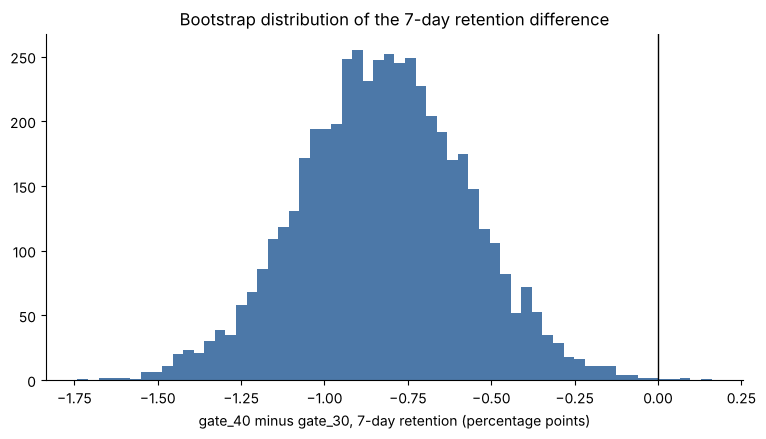

In [5]:
rng = np.random.default_rng(42)
r7 = {v: ab.loc[ab.version == v, "retention_7"].to_numpy(dtype=float) for v in ["gate_30", "gate_40"]}
B = 5000
boot = np.array([rng.choice(r7["gate_40"], r7["gate_40"].size).mean() - rng.choice(r7["gate_30"], r7["gate_30"].size).mean()
                 for _ in range(B)])
boot_ci = np.percentile(boot, [2.5, 97.5]) * 100
prob_worse = (boot < 0).mean()
fig, ax = plt.subplots()
ax.hist(boot * 100, bins=60, color="#4C78A8")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("gate_40 minus gate_30, 7-day retention (percentage points)")
ax.set_title("Bootstrap distribution of the 7-day retention difference")
fig.savefig(FIG / "p07_bootstrap_retention7.png", dpi=150, bbox_inches="tight")
print(f"bootstrap 95% CI: {boot_ci[0]:.2f} to {boot_ci[1]:.2f} pp; share of resamples where gate_40 is lower: {prob_worse:.1%}")

## 7.5 Engagement check: game rounds
Rounds are very skewed (most players stop early, a few play thousands), so means are fragile. Mann-Whitney U compares the distributions without assuming normality. One extreme player is reported, not silently dropped.

In [6]:
print(ab.groupby("version").sum_gamerounds.describe().round(1).to_string())
top_player = ab.loc[ab.sum_gamerounds.idxmax()]
print(f"\nMost extreme player: {int(top_player.sum_gamerounds):,} rounds ({top_player.version})")
u, mw_p = stats.mannwhitneyu(ab.loc[ab.version == "gate_30", "sum_gamerounds"],
                             ab.loc[ab.version == "gate_40", "sum_gamerounds"], alternative="two-sided")
medians = ab.groupby("version").sum_gamerounds.median()
print(f"Mann-Whitney U p = {mw_p:.4g}; medians: gate_30 {medians['gate_30']:.0f}, gate_40 {medians['gate_40']:.0f}")

              count    mean      std    min    25%     50%     75%         max
version                                                                       
gate_30 44,700.0000 52.5000 256.7000 0.0000 5.0000 17.0000 50.0000 49,854.0000
gate_40 45,489.0000 51.3000 103.3000 0.0000 5.0000 16.0000 52.0000  2,640.0000

Most extreme player: 49,854 rounds (gate_30)
Mann-Whitney U p = 0.05021; medians: gate_30 17, gate_40 16


## 7.6 Decision
The recommendation is generated from the numbers above; the reasoning and caveats are written in `docs/walkthroughs/phase-07-ab-test.md`.

In [7]:
r7row, r1row = results.loc["retention_7"], results.loc["retention_1"]
if r7row.p_value < 0.05 and r7row.diff_pp < 0:
    decision = "DON'T SHIP gate_40: it significantly lowers 7-day retention."
elif r7row.p_value < 0.05 and r7row.diff_pp > 0:
    decision = "SHIP gate_40: it significantly raises 7-day retention."
else:
    decision = "NO DECISION from this test: the 7-day retention difference is not significant."
print(decision)
print(f"7-day retention: {r7row.rate_gate_30:.2%} -> {r7row.rate_gate_40:.2%} "
      f"({r7row.diff_pp:+.2f} pp, 95% CI {r7row.diff_ci_low_pp:.2f} to {r7row.diff_ci_high_pp:.2f}, p={r7row.p_value:.4f})")
if srm_p < 0.01:
    print("CAVEAT: SRM detected - investigate assignment before trusting any result.")

save_result("phase07_ab_test", {
    "dataset": "Cookie Cats (Tactile Entertainment), public A/B test data",
    "file_sha256": sha256, "rows": int(len(ab)),
    "group_sizes": {k: int(v) for k, v in counts.items()},
    "srm": {"chi2": float(chi2), "p_value": float(srm_p), "detected_at_0.01": bool(srm_p < 0.01)},
    "retention": results.reset_index().to_dict("records"),
    "retention_7_bootstrap_ci_pp": [float(boot_ci[0]), float(boot_ci[1])],
    "retention_7_share_of_bootstrap_resamples_gate40_lower": float(prob_worse),
    "gamerounds": {"median_gate_30": float(medians["gate_30"]), "median_gate_40": float(medians["gate_40"]),
                   "mannwhitney_p": float(mw_p), "max_rounds_one_player": int(top_player.sum_gamerounds)},
    "decision": decision,
})

DON'T SHIP gate_40: it significantly lowers 7-day retention.
7-day retention: 19.02% -> 18.20% (-0.82 pp, 95% CI -1.33 to -0.31, p=0.0016)
CAVEAT: SRM detected - investigate assignment before trusting any result.
saved -> results/phase07_ab_test.json


PosixPath('/home/claude/streampulse/results/phase07_ab_test.json')